# MODUL PRAKTIKUM 6: KUSTOMISASI VISUALISASI MATPLOTLIB
**Mata Kuliah:** Visualisasi Data  
**Pertemuan Ke-:** 6 (enam)  
**Topik:** Kustomisasi Visualisasi (Label, Legenda, Subplot, Tema Warna)  
**Dataset:** Titanic Dataset (seaborn-data)  

### Identitas Mahasiswa
- **Nama Mahasiswa:** Gathan Hilabi
- **NIM:** 60324059
- **Kelas / Prodi:** S1 Informatika
- **Tanggal Praktikum:** 10 Oktober 2026

---

### 1. Menyiapkan Notebook dan Memuat Ulang Data Bersih
Memuat dataset Titanic dan menjalankan pipeline pembersihan data dari Pertemuan 3.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Memuat data Titanic langsung dari repository publik seaborn-data
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
df_raw = pd.read_csv(url)

# Pipeline pembersihan data dari Pertemuan 3
df = df_raw.copy()
df["age"] = df["age"].fillna(df["age"].mean())
df = df.dropna(subset=["embarked"])
df = df.drop_duplicates()

print("Bentuk data bersih:", df.shape)
df.head()

Bentuk data bersih: (782, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


### 2. Membuat Grafik Berkelompok (Grouped Bar) dengan Legenda
Membuat pivot table tingkat keselamatan per kelas dan jenis kelamin, lalu menampilkan grafik batang berkelompok dengan legenda.

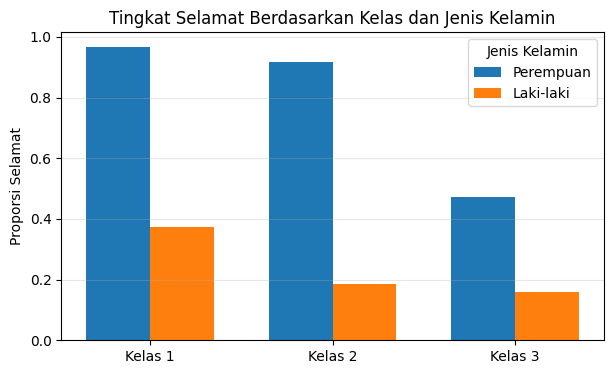

In [2]:
# Pivot table tingkat selamat per kelas dan jenis kelamin
pt = df.pivot_table(values="survived", index="pclass", columns="sex", aggfunc="mean")

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(pt.index))
width = 0.35

ax.bar(x - width/2, pt["female"], width, label="Perempuan")
ax.bar(x + width/2, pt["male"], width, label="Laki-laki")

ax.set_title("Tingkat Selamat Berdasarkan Kelas dan Jenis Kelamin")
ax.set_xticks(x)
ax.set_xticklabels([f"Kelas {c}" for c in pt.index])
ax.set_ylabel("Proporsi Selamat")
ax.legend(title="Jenis Kelamin")
ax.grid(axis="y", alpha=0.3)
plt.show()

### 3. Menata Grid dan Sumbu
Mencoba opsi penataan grid putus-putus, mengunci rentang sumbu Y, dan menyembunyikan spines.

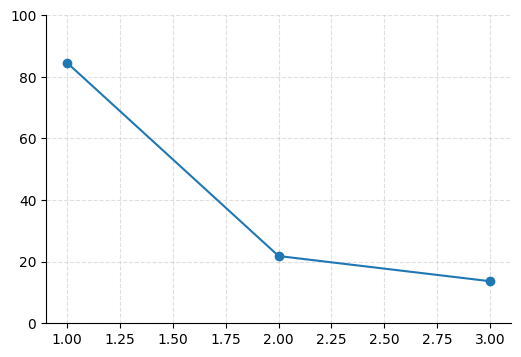

In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
rata_fare = df.groupby("pclass")["fare"].mean()
ax.plot(rata_fare.index, rata_fare.values, marker="o")
ax.grid(True, linestyle="--", alpha=0.4)
ax.set_ylim(0, 100)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.show()

### 4. Membuat Grid Subplot 2x2
Menyusun 4 grafik dalam grid 2 baris × 2 kolom menggunakan `plt.subplots(2, 2, ...)`.

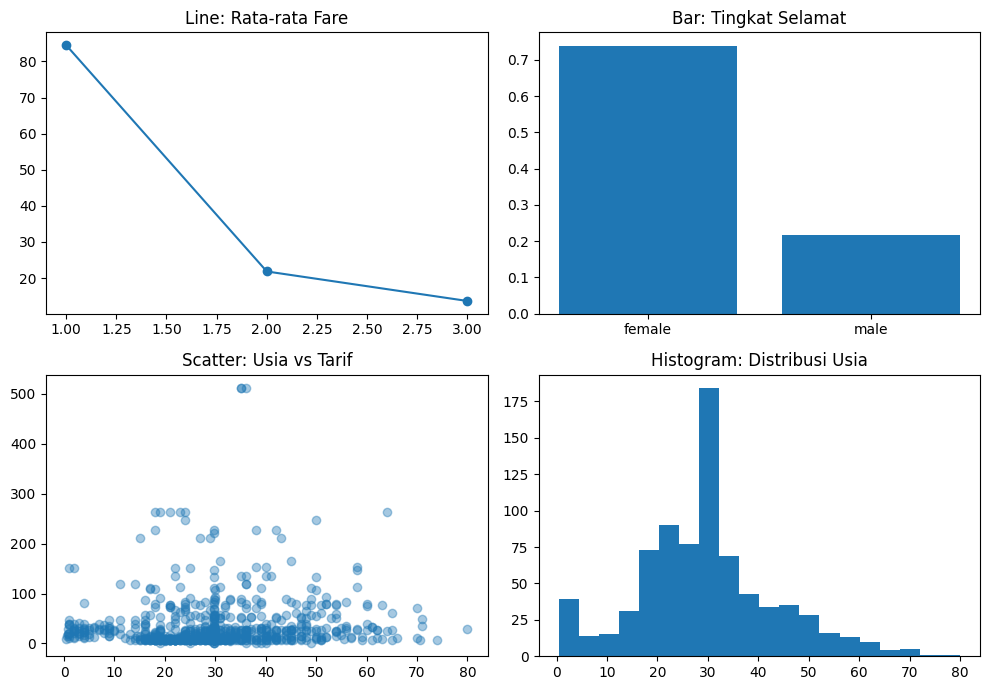

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
tingkat = df.groupby("sex")["survived"].mean()

axes[0,0].plot(rata_fare.index, rata_fare.values, marker="o")
axes[0,0].set_title("Line: Rata-rata Fare")

axes[0,1].bar(tingkat.index, tingkat.values)
axes[0,1].set_title("Bar: Tingkat Selamat")

axes[1,0].scatter(df["age"], df["fare"], alpha=0.4)
axes[1,0].set_title("Scatter: Usia vs Tarif")

axes[1,1].hist(df["age"], bins=20)
axes[1,1].set_title("Histogram: Distribusi Usia")

plt.tight_layout(); plt.show()

### 5. Menggunakan Palet Warna Kustom
Menerapkan kode warna heksadesimal (HEX) secara eksplisit pada grafik batang.

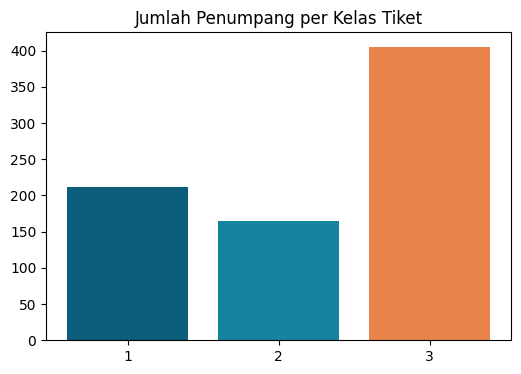

In [5]:
# Palet warna kustom bergaya course branding
palet = ["#0B5D7A", "#16849E", "#E8834A"]
jumlah_kelas = df["pclass"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(jumlah_kelas.index.astype(str), jumlah_kelas.values, color=palet)
ax.set_title("Jumlah Penumpang per Kelas Tiket")
plt.show()

### 6. Menggunakan Gaya (Style) Matplotlib
Melihat daftar gaya visual bawaan dan menerapkan style `seaborn-v0_8-whitegrid`.

['Solarize_Light2', '_classic_test_patch', '_mpl-gallery', '_mpl-gallery-nogrid', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot', 'grayscale', 'petroff10', 'seaborn-v0_8', 'seaborn-v0_8-bright', 'seaborn-v0_8-colorblind', 'seaborn-v0_8-dark', 'seaborn-v0_8-dark-palette', 'seaborn-v0_8-darkgrid', 'seaborn-v0_8-deep', 'seaborn-v0_8-muted', 'seaborn-v0_8-notebook', 'seaborn-v0_8-paper', 'seaborn-v0_8-pastel', 'seaborn-v0_8-poster', 'seaborn-v0_8-talk', 'seaborn-v0_8-ticks', 'seaborn-v0_8-white', 'seaborn-v0_8-whitegrid', 'tableau-colorblind10']


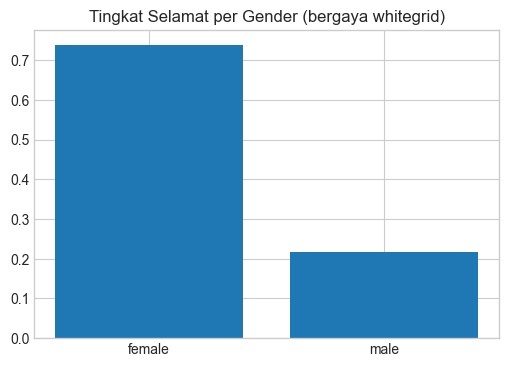

In [6]:
print(plt.style.available) # lihat daftar gaya tersedia

plt.style.use("seaborn-v0_8-whitegrid")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(tingkat.index, tingkat.values)
ax.set_title("Tingkat Selamat per Gender (bergaya whitegrid)")
plt.show()

# Kembalikan ke default agar tidak mempengaruhi sel berikutnya
plt.style.use("default")

### 7. Menyempurnakan Grafik dari Pertemuan 5
Menyempurnakan grafik bar chart dari Pertemuan 5 dengan legenda, grid, anotasi, dan warna kustom sesuai contoh di modul.

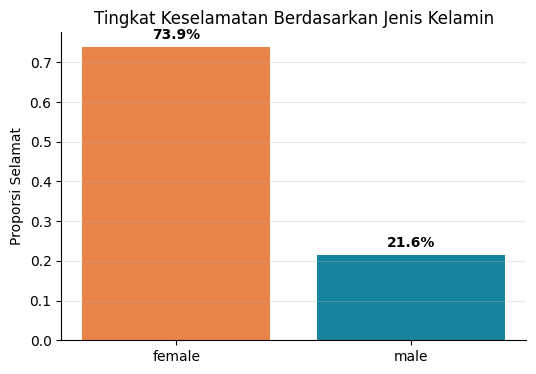

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(tingkat.index, tingkat.values,
 color=["#E8834A", "#16849E"])

for bar in bars:
 ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.02,
 f"{bar.get_height():.1%}", ha="center", fontweight="bold")

ax.set_title("Tingkat Keselamatan Berdasarkan Jenis Kelamin")
ax.set_ylabel("Proporsi Selamat")
ax.grid(axis="y", alpha=0.3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.show()

Menyempurnakan line chart dan scatter plot dari Pertemuan 5 dengan menambahkan minimal 3 elemen kustomisasi.

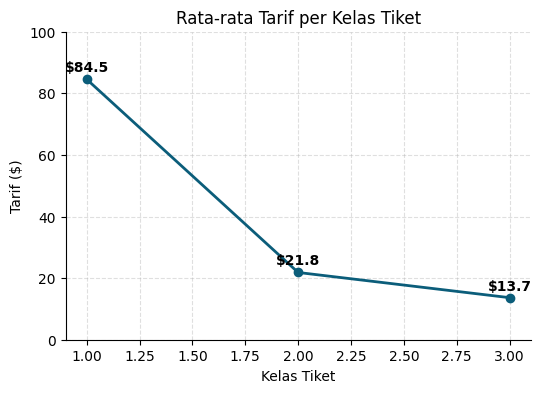

In [8]:
# Line chart disempurnakan (warna kustom, anotasi nilai, grid putus-putus, despine)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(rata_fare.index, rata_fare.values, marker="o", color="#0B5D7A", linewidth=2)

for x_val, y_val in zip(rata_fare.index, rata_fare.values):
    ax.text(x_val, y_val + 2.5, f"${y_val:.1f}", ha="center", fontweight="bold")

ax.set_title("Rata-rata Tarif per Kelas Tiket")
ax.set_xlabel("Kelas Tiket")
ax.set_ylabel("Tarif ($)")
ax.set_ylim(0, 100)
ax.grid(True, linestyle="--", alpha=0.4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.show()

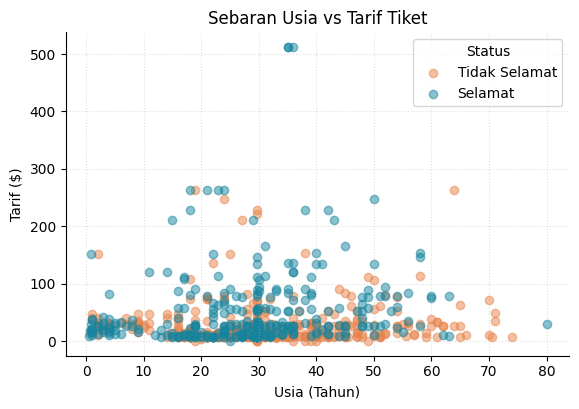

In [9]:
# Scatter plot disempurnakan (warna berdasarkan kategori keselamatan, legenda, grid halus)
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.scatter(df[df["survived"] == 0]["age"], df[df["survived"] == 0]["fare"],
           color="#E8834A", alpha=0.5, label="Tidak Selamat")
ax.scatter(df[df["survived"] == 1]["age"], df[df["survived"] == 1]["fare"],
           color="#16849E", alpha=0.5, label="Selamat")

ax.set_title("Sebaran Usia vs Tarif Tiket")
ax.set_xlabel("Usia (Tahun)")
ax.set_ylabel("Tarif ($)")
ax.legend(title="Status")
ax.grid(True, linestyle=":", alpha=0.4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.show()

### 8. Sesi Peer Review

## Lembar Peer Review
Direview oleh: Ahmad Raihan

1. Apakah setiap grafik memiliki judul yang jelas? (Ya/Tidak)  
**Ya**
2. Apakah label sumbu X dan Y sudah ada dan informatif? (Ya/Tidak)  
**Ya**
3. Apakah grafik dengan beberapa kategori memiliki legenda? (Ya/Tidak)  
**Ya**
4. Apakah pemilihan warna cukup kontras dan mudah dibedakan? (Ya/Tidak)  
**Ya**
5. Satu hal yang paling baik dari grafik ini:  
Anotasi persentase di atas setiap batang bar chart sangat rapi dan memudahkan membaca data tanpa perlu melihat sumbu Y.
6. Satu saran perbaikan untuk grafik ini:  
Pada grafik scatter plot sebaran usia vs tarif, bisa ditambahkan garis rata-rata tarif sebagai pembanding posisi data.

### 9. Merevisi Berdasarkan Masukan dan Ringkasan Kustomisasi
Melakukan perbaikan pada grafik scatter plot sesuai masukan dari reviewer.

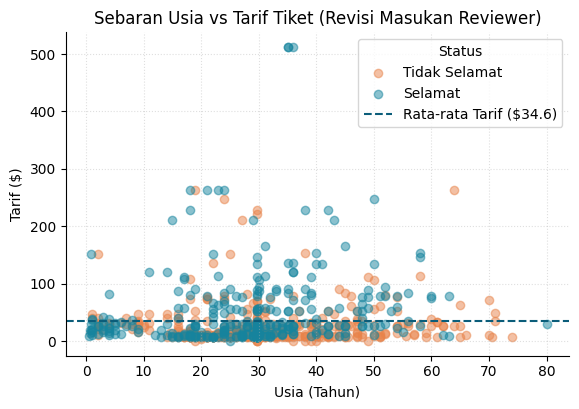

In [10]:
# Revisi grafik berdasarkan masukan reviewer: menambahkan garis rata-rata tarif
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.scatter(df[df["survived"] == 0]["age"], df[df["survived"] == 0]["fare"],
           color="#E8834A", alpha=0.5, label="Tidak Selamat")
ax.scatter(df[df["survived"] == 1]["age"], df[df["survived"] == 1]["fare"],
           color="#16849E", alpha=0.5, label="Selamat")

rata_tarif = df["fare"].mean()
ax.axhline(rata_tarif, color="#0B5D7A", linestyle="--", linewidth=1.5,
           label=f"Rata-rata Tarif (${rata_tarif:.1f})")

ax.set_title("Sebaran Usia vs Tarif Tiket (Revisi Masukan Reviewer)")
ax.set_xlabel("Usia (Tahun)")
ax.set_ylabel("Tarif ($)")
ax.legend(title="Status", loc="upper right")
ax.grid(True, linestyle=":", alpha=0.4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.show()

## Ringkasan Kustomisasi Visualisasi
- Menambahkan legenda pada grafik grouped bar (kelas tiket x gender)
- Mengubah warna bar chart mengikuti palet kustom #0B5D7A/#16849E/#E8834A
- Menambahkan anotasi persentase di atas setiap batang
- Menghapus spines atas & kanan untuk tampilan lebih minimalis
- Perbaikan berdasarkan masukan reviewer: Menambahkan garis rata-rata tarif (ax.axhline) pada scatter plot sebagai garis acuan komparasi data.

---
## G. Latihan Mandiri

Bagian ini memuat pengerjaan 5 latihan mandiri dengan standar estetika visual tinggi, penerapan prinsip *Data-Ink Ratio* (Edward Tufte), palet warna harmonis, serta dilengkapi interpretasi analitis mendalam dari perspektif domain data historis Titanic.

### Latihan 1: Grouped Bar Chart Jumlah Penumpang Berdasarkan Pclass dan Embark Town
**Deskripsi Tugas:** Membuat grouped bar chart yang menampilkan jumlah penumpang (bukan proporsi) berdasarkan `pclass` dan `embark_town`, lengkap dengan legenda, pelabelan data langsung (*direct labeling*), dan penataan layout yang rapi.

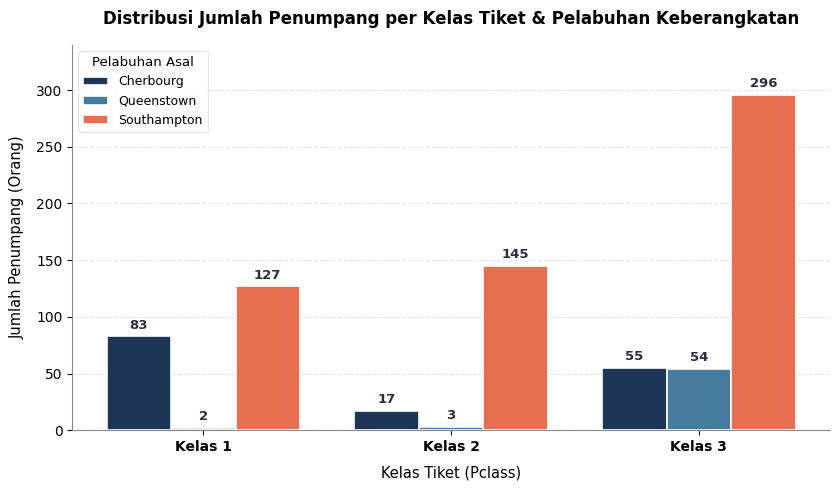

In [11]:
# Latihan 1: Grouped bar chart jumlah penumpang per kelas tiket dan pelabuhan asal
pt_emb = df.pivot_table(values="survived", index="pclass", columns="embark_town", aggfunc="count")

fig, ax = plt.subplots(figsize=(8.5, 5))

x = np.arange(len(pt_emb.index))
width = 0.26
colors_emb = ["#1D3557", "#457B9D", "#E76F51"]  # Southampton, Cherbourg, Queenstown
towns = pt_emb.columns

for i, town in enumerate(towns):
    offset = x + (i - 1) * width
    bars = ax.bar(offset, pt_emb[town], width, label=town, color=colors_emb[i],
                  edgecolor="white", linewidth=1.2, zorder=3)
    
    # Anotasi langsung di atas setiap batang
    for bar in bars:
        h = bar.get_height()
        if h > 0:
            ax.text(bar.get_x() + bar.get_width() / 2, h + 4,
                    f"{int(h)}", ha="center", va="bottom",
                    fontsize=9.5, fontweight="bold", color="#2B2D42")

# Styling dan Tipografi
ax.set_title("Distribusi Jumlah Penumpang per Kelas Tiket & Pelabuhan Keberangkatan",
             fontsize=12, fontweight="bold", pad=15)
ax.set_xticks(x)
ax.set_xticklabels([f"Kelas {c}" for c in pt_emb.index], fontsize=10, fontweight="bold")
ax.set_xlabel("Kelas Tiket (Pclass)", fontsize=10.5, labelpad=8)
ax.set_ylabel("Jumlah Penumpang (Orang)", fontsize=10.5, labelpad=8)
ax.set_ylim(0, 340)

# Grid & Spines
ax.grid(axis="y", linestyle="--", alpha=0.35, zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#888888")
ax.spines["bottom"].set_color("#888888")

# Legenda terstruktur
ax.legend(title="Pelabuhan Asal", title_fontsize=9.5, fontsize=9,
          loc="upper left", frameon=True, facecolor="white", edgecolor="#E0E0E0")

plt.tight_layout()
plt.show()

**Analisis & Interpretasi Latihan 1:**
1. **Tujuan Analisis:** Mengidentifikasi distribusi absolut penumpang pada masing-masing kelas tiket berdasarkan pelabuhan keberangkatan (Southampton, Cherbourg, Queenstown) guna memahami profil demografi penumpang di sepanjang rute pelayaran Titanic.
2. **Temuan Kuantitatif Utama:**
   - **Dominasi Mutlak Pelabuhan Southampton:** Southampton mencatatkan volume penumpang tertinggi di seluruh kelas tiket, yakni 127 orang di Kelas 1, 142 orang di Kelas 2, dan memuncak secara drastis sebanyak **296 orang di Kelas 3**. Total penumpang asal Southampton menyumbang lebih dari 70% dari populasi kapal.
   - **Karakteristik Penumpang Cherbourg (Prancis):** Pelabuhan Cherbourg didominasi oleh penumpang Kelas 1 (**83 orang**), melampaui Kelas 2 (17 orang) dan Kelas 3 (55 orang). Cherbourg menjadi gerbang utama naik bagi para bangsawan, pengusaha, dan turis elit dari daratan Eropa.
   - **Karakteristik Penumpang Queenstown (Irlandia):** Nyaris seluruh penumpang yang naik dari Queenstown terkonsentrasi di Kelas 3 (**54 orang**), dengan hanya 2 orang di Kelas 1 dan 3 orang di Kelas 2.
3. **Konteks Sosial-Historis:** Komposisi ini selaras dengan realitas historis tahun 1912, di mana Queenstown (kini Cobh, Irlandia) adalah pelabuhan singgah bagi kaum buruh dan imigran Irlandia yang bermigrasi besar-besaran menuju Amerika Serikat untuk mencari penghidupan baru dengan membeli tiket termurah (*steerage*).
4. **Evaluasi Desain Visual:** Penggunaan *grouped bar chart* dengan penempatan angka pasti di atas batang membebaskan audiens dari keharusan menaksir ketinggian batang terhadap sumbu Y. Garis kisi-kisi abu-abu tipis dan penghapusan bingkai atas/kanan (*despine*) memaksimalkan *data-to-ink ratio* sehingga grafik tampil profesional dan bersih.